# Mini-project 5: Taxi route pricing and fleet planning

Ntinda counts come from the original question; Entebbe and Mukono counts are illustrative. Ten daily observations cannot establish an annual demand pattern.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("Open Jupyter in the correct folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.taxi import (Route, MovingAverage, ExponentialSmoothing, LinearTrend,
                      equilibrium, walk_forward, vehicles_needed)

routes = [Route('Kampala–Ntinda',[35,40,42,50,55,60,48,52,47,45],2000),
          Route('Kampala–Entebbe',[60,58,65,70,72,80,75,68,66,64],5000),
          Route('Kampala–Mukono',[45,47,50,49,55,62,58,53,51,50],3000)]
print(pd.DataFrame([{'route':r.name,'fare UGX':r.fare,
    'daily revenue UGX':r.daily_revenue().astype(int).tolist(),
    'total revenue UGX':r.total_revenue(),**r.statistics()} for r in routes]
    ).set_index('route').round(2).to_string())
fare, quantity = equilibrium()
print('Equilibrium fare UGX:',fare,'equilibrium passengers per trip-hour:',quantity)
print('UGX 2,000 is below the model equilibrium price of UGX 2,200.')
print('Demand at 2,000:',120-.02*2000,'supply at 2,000:',10+.03*2000,
      'so the model implies excess demand of', (120-.02*2000)-(10+.03*2000))

                 fare UGX                                                                 daily revenue UGX  total revenue UGX  mean  variance  std_dev
route                                                                                                                                                  
Kampala–Ntinda     2000.0        [70000, 80000, 84000, 100000, 110000, 120000, 96000, 104000, 94000, 90000]           948000.0  47.4     54.27     7.37
Kampala–Entebbe    5000.0  [300000, 290000, 325000, 350000, 360000, 400000, 375000, 340000, 330000, 320000]          3390000.0  67.8     45.07     6.71
Kampala–Mukono     3000.0  [135000, 141000, 150000, 147000, 165000, 186000, 174000, 159000, 153000, 150000]          1560000.0  52.0     26.44     5.14
Equilibrium fare UGX: 2200.0 equilibrium passengers per trip-hour: 76.0
UGX 2,000 is below the model equilibrium price of UGX 2,200.
Demand at 2,000: 80.0 supply at 2,000: 70.0 so the model implies excess demand of 10.0


## Rolling-origin backtest

For days 4–10, fit using days strictly before the forecast day. Tune smoothing alpha on a small grid using the same backtest and choose by MAE; the MAE after tuning is somewhat optimistic because no independent validation period remains. The three-day moving average uses the last three observed counts.

In [2]:
alpha_grid = [.2,.4,.6,.8,1.0]
records, best_by_route, backtest_predictions = [], {}, {}
for route in routes:
    candidates = {'3-day mean':MovingAverage, 'linear trend':LinearTrend}
    tuned_alpha = min(alpha_grid,key=lambda a:walk_forward(
        route.counts, lambda:ExponentialSmoothing(a))[0])
    # Test each model on days 4–10 using only earlier passenger counts.
    candidates[f'smoothing alpha={tuned_alpha}'] = lambda a=tuned_alpha:ExponentialSmoothing(a)
    outcomes = {}
    for name, factory in candidates.items():
        mae,preds = walk_forward(route.counts,factory)
        records.append({'route':route.name,'model':name,'MAE passengers':mae})
        outcomes[name] = (factory, preds, mae)
    winner = min(outcomes,key=lambda n:outcomes[n][2])
    best_by_route[route.name] = outcomes[winner][0]
    backtest_predictions[route.name] = outcomes[winner][1]
    print(route.name,'best:',winner,'alpha grid winner:',tuned_alpha)
print(pd.DataFrame(records).set_index(['route','model']).round(2).to_string())

plan = []
for route in routes:
    forecast_count = max(0, best_by_route[route.name]().fit(route.counts).predict())
    # Add the 15% buffer before dividing by 14 seats × 8 trips per vehicle.
    plan.append({'route':route.name,'day 11 passengers':forecast_count,
                 'day 11 revenue UGX':forecast_count*route.fare,
                 'vehicles with 15% buffer':vehicles_needed(forecast_count)})
fleet_plan = pd.DataFrame(plan).set_index('route')
print('\nDay 11 fleet plan:\n',fleet_plan.round(2).to_string())
print('Hand check: one vehicle offers 14 seats × 8 trips = 112 passenger places/day; apply a 15% demand buffer before rounding up.')

Kampala–Ntinda best: smoothing alpha=1.0 alpha grid winner: 1.0
Kampala–Entebbe best: smoothing alpha=1.0 alpha grid winner: 1.0
Kampala–Mukono best: smoothing alpha=1.0 alpha grid winner: 1.0
                                     MAE passengers
route           model                              
Kampala–Ntinda  3-day mean                     7.52
                linear trend                   7.87
                smoothing alpha=1.0            5.86
Kampala–Entebbe 3-day mean                     7.19
                linear trend                   7.71
                smoothing alpha=1.0            4.43
Kampala–Mukono  3-day mean                     5.33
                linear trend                   6.39
                smoothing alpha=1.0            3.71

Day 11 fleet plan:
                  day 11 passengers  day 11 revenue UGX  vehicles with 15% buffer
route                                                                           
Kampala–Ntinda                45.0             90000

## Revenue plot

Backtest predictions shown on days 4–10 were made using only previous days; day 11 uses all ten observations.

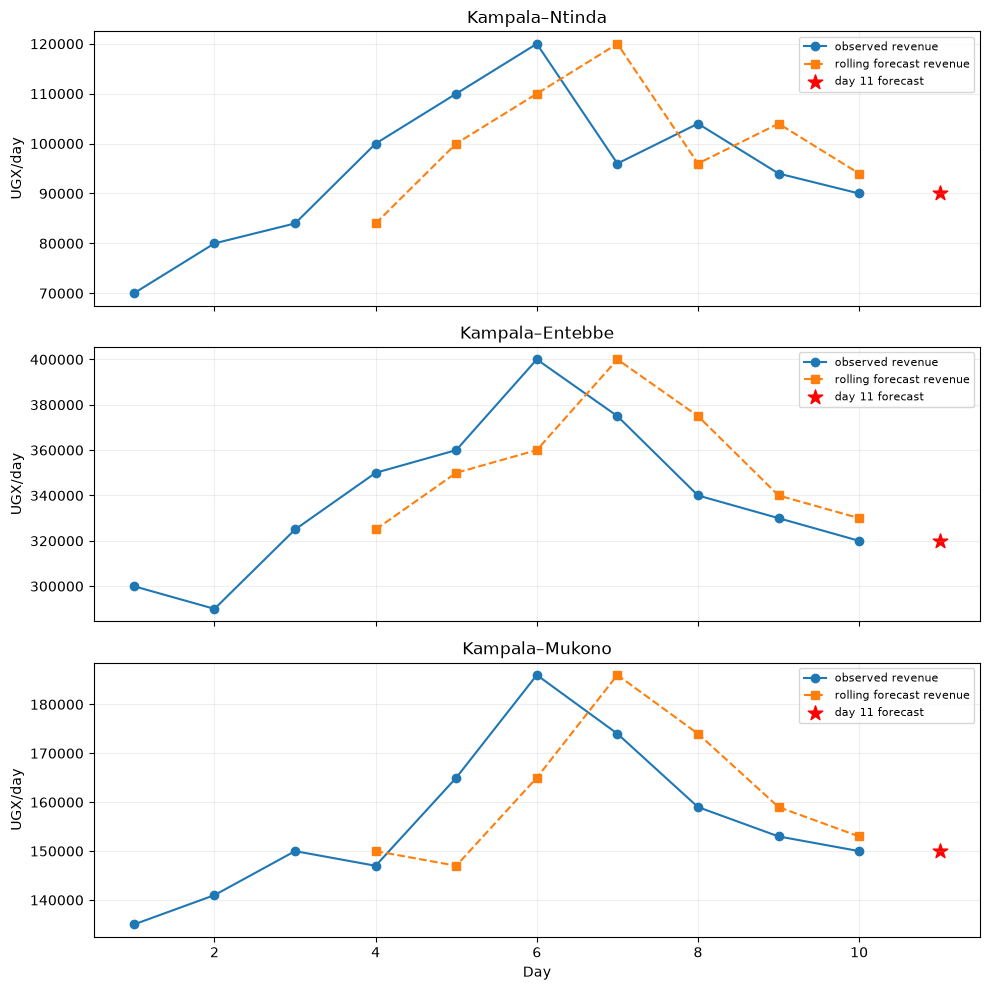

In [4]:
fig, axes = plt.subplots(3,1,figsize=(10,10),sharex=True)
for ax,route in zip(axes,routes):
    ax.plot(range(1,11),route.daily_revenue(),'o-',label='observed revenue')
    ax.plot(range(4,11),backtest_predictions[route.name]*route.fare,'s--',
            label='rolling forecast revenue')
    ax.scatter([11],[fleet_plan.loc[route.name,'day 11 revenue UGX']],marker='*',
               s=120,color='red',label='day 11 forecast')
    ax.set(ylabel='UGX/day',title=route.name)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
axes[-1].set_xlabel('Day')
fig.tight_layout()
plt.show()

## Findings & Limitations

The fare-equilibrium equations give P = UGX 2,200 and Q = 76 passengers per trip-hour. At the current Ntinda fare of UGX 2,000, the hypothetical demand curve gives 80 and the supply curve 70, or excess demand of ten passengers per trip-hour. This is an interpretation of the supplied equations, not an instruction to change fares: fares and passenger counts refer to different units (trip-hour versus a whole day), and the curves are assumed rather than measured from the ten-day sample.

The rolling-origin table tests the three-day moving average, tuned exponential smoothing and a linear trend on days 4–10. Selection uses passenger MAE. Day 11 predicted passenger counts are multiplied by the stated fares to obtain gross revenue, without deducting fuel, wages or route fees. Each vehicle can provide at most 112 passenger places in eight one-way trips. The displayed fleet sizes include a 15% passenger buffer and round upward to whole vehicles; these are capacity estimates rather than an optimized timetable.

Only ten days are available, so the model cannot learn weekly or holiday patterns reliably. Choosing smoothing alpha on the same seven test origins used to report its MAE gives a somewhat optimistic score. The Entebbe and Mukono routes are illustrative. Actual deployment would require measured trip-level occupancy, realistic travel times and turnarounds, operating costs, vehicle availability, and demand by hour. None of the displayed gross revenue values is a profit estimate.